In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_1.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_10.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_100.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_101.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_102.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_103.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_104.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_105.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_106.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_107.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_108.h5
/kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TestData/img/image_109.h5
/kaggle

In [4]:

import os

BASE_PATH = "/kaggle/input"

for dirname, subdirs, filenames in os.walk(BASE_PATH):
    level = dirname.replace(BASE_PATH, "").count(os.sep)
    
    if level <= 4:
        indent = "    " * level
        print(f"{indent}{os.path.basename(dirname)}/")
        
        for filename in filenames[:5]:
            print(f"{indent}    {filename}")


input/
    datasets/
        tekbahadurkshetri/
            landslide4sense/
                TestData/
                TrainData/
                ValidData/


In [5]:

import os

DATASET_PATH = "/kaggle/input/datasets/tekbahadurkshetri/landslide4sense"

for folder in ["TrainData", "ValidData", "TestData"]:
    path = os.path.join(DATASET_PATH, folder)

    print(f"\n{'='*50}")
    print(folder)

    for root, dirs, files in os.walk(path):
        level = root.replace(path, "").count(os.sep)

        if level <= 2:
            print("  " * level + os.path.basename(root) + "/")

            for file in files[:8]:
                print("  " * (level + 1) + file)

            if level >= 2:
                dirs[:] = []



TrainData
TrainData/
  img/
    image_1.h5
    image_10.h5
    image_100.h5
    image_1000.h5
    image_1001.h5
    image_1002.h5
    image_1003.h5
    image_1004.h5
  mask/
    mask_1.h5
    mask_10.h5
    mask_100.h5
    mask_1000.h5
    mask_1001.h5
    mask_1002.h5
    mask_1003.h5
    mask_1004.h5

ValidData
ValidData/
  img/
    image_1.h5
    image_10.h5
    image_100.h5
    image_101.h5
    image_102.h5
    image_103.h5
    image_104.h5
    image_105.h5

TestData
TestData/
  img/
    image_1.h5
    image_10.h5
    image_100.h5
    image_101.h5
    image_102.h5
    image_103.h5
    image_104.h5
    image_105.h5


In [6]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import h5py
import cv2

from pathlib import Path
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Dataset paths
DATASET_PATH = Path(
    "/kaggle/input/datasets/tekbahadurkshetri/landslide4sense"
)

TRAIN_PATH = DATASET_PATH / "TrainData"
VALID_PATH = DATASET_PATH / "ValidData"
TEST_PATH = DATASET_PATH / "TestData"

# Output directory
OUTPUT_PATH = Path("/kaggle/working/landslide_project")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

print("\nDataset exists:", DATASET_PATH.exists())
print("Training folder:", TRAIN_PATH.exists())
print("Validation folder:", VALID_PATH.exists())
print("Testing folder:", TEST_PATH.exists())


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Dataset exists: True
Training folder: True
Validation folder: True
Testing folder: True


In [7]:

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU available!")
    for gpu in gpus:
        print(gpu)
else:
    print("No GPU detected. Enable GPU in Kaggle Notebook settings.")


GPU available!
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')


In [8]:

for folder_name, folder_path in [
    ("Training", TRAIN_PATH),
    ("Validation", VALID_PATH),
    ("Testing", TEST_PATH)
]:
    files = [f for f in folder_path.rglob("*") if f.is_file()]

    print(f"\n{folder_name}: {len(files)} files")

    extensions = {}
    for file in files:
        extensions[file.suffix] = extensions.get(file.suffix, 0) + 1

    print("File formats:", extensions)

    print("Sample filenames:")
    for file in files[:10]:
        print(" ", file.name)



Training: 7598 files
File formats: {'.h5': 7598}
Sample filenames:
  image_1.h5
  image_10.h5
  image_100.h5
  image_1000.h5
  image_1001.h5
  image_1002.h5
  image_1003.h5
  image_1004.h5
  image_1005.h5
  image_1006.h5

Validation: 245 files
File formats: {'.h5': 245}
Sample filenames:
  image_1.h5
  image_10.h5
  image_100.h5
  image_101.h5
  image_102.h5
  image_103.h5
  image_104.h5
  image_105.h5
  image_106.h5
  image_107.h5

Testing: 800 files
File formats: {'.h5': 800}
Sample filenames:
  image_1.h5
  image_10.h5
  image_100.h5
  image_101.h5
  image_102.h5
  image_103.h5
  image_104.h5
  image_105.h5
  image_106.h5
  image_107.h5


In [9]:

import h5py

h5_files = list(TRAIN_PATH.rglob("*.h5"))

print("HDF5 files found:", len(h5_files))

if h5_files:
    sample_file = h5_files[0]

    with h5py.File(sample_file, "r") as f:
        print("\nSample:", sample_file.name)
        print("Datasets:", list(f.keys()))

        for key in f.keys():
            data = f[key]
            print(
                key,
                "| Shape:", data.shape,
                "| Data type:", data.dtype
            )


HDF5 files found: 7598

Sample: image_1.h5
Datasets: ['img']
img | Shape: (128, 128, 14) | Data type: float64


In [10]:

# Inspect the folder structure inside TrainData

for root, dirs, files in os.walk(TRAIN_PATH):
    print("\nFolder:", root)
    print("Subfolders:", dirs)

    print("Sample files:")
    for file in files[:10]:
        print(" ", file)

    if root.count(os.sep) - str(TRAIN_PATH).count(os.sep) >= 2:
        dirs[:] = []



Folder: /kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TrainData
Subfolders: ['img', 'mask']
Sample files:

Folder: /kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TrainData/img
Subfolders: []
Sample files:
  image_1.h5
  image_10.h5
  image_100.h5
  image_1000.h5
  image_1001.h5
  image_1002.h5
  image_1003.h5
  image_1004.h5
  image_1005.h5
  image_1006.h5

Folder: /kaggle/input/datasets/tekbahadurkshetri/landslide4sense/TrainData/mask
Subfolders: []
Sample files:
  mask_1.h5
  mask_10.h5
  mask_100.h5
  mask_1000.h5
  mask_1001.h5
  mask_1002.h5
  mask_1003.h5
  mask_1004.h5
  mask_1005.h5
  mask_1006.h5


In [12]:

import h5py
import numpy as np
from pathlib import Path

def load_dataset(split):
    split_path = DATASET_PATH / split

    img_dir = split_path / "img"
    mask_dir = split_path / "mask"

    image_files = sorted(
        img_dir.glob("image_*.h5"),
        key=lambda x: int(x.stem.split("_")[1])
    )

    X, Y = [], []

    for image_file in image_files:
        image_id = image_file.stem.split("_")[1]
        mask_file = mask_dir / f"mask_{image_id}.h5"

        if not mask_file.exists():
            continue

        with h5py.File(image_file, "r") as f:
            image = f["img"][:]

        with h5py.File(mask_file, "r") as f:
            mask = f["mask"][:]

        X.append(image)
        Y.append(mask)

    return np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32)


X_train, Y_train = load_dataset("TrainData")
X_val, Y_val = load_dataset("ValidData")

print("Training images:", X_train.shape)
print("Training masks:", Y_train.shape)
print("Validation images:", X_val.shape)
print("Validation masks:", Y_val.shape)


Training images: (3799, 128, 128, 14)
Training masks: (3799, 128, 128)
Validation images: (0,)
Validation masks: (0,)


In [11]:

import re
import h5py
import numpy as np

def get_number(filename):
    match = re.search(r'_(\d+)\.h5$', filename)
    return int(match.group(1)) if match else None

for split in ["TrainData", "ValidData", "TestData"]:

    split_path = DATASET_PATH / split

    img_path = split_path / "img"
    mask_path = split_path / "mask"

    images = sorted(img_path.glob("image_*.h5"),
                    key=lambda x: get_number(x.name))

    print(f"\n{split}")
    print("Images:", len(images))

    if mask_path.exists():
        masks = sorted(mask_path.glob("mask_*.h5"),
                       key=lambda x: get_number(x.name))

        print("Masks:", len(masks))

        image_ids = {get_number(f.name) for f in images}
        mask_ids = {get_number(f.name) for f in masks}

        print("Missing masks:", len(image_ids - mask_ids))
        print("Missing images:", len(mask_ids - image_ids))

        if masks:
            sample_mask = masks[0]

            with h5py.File(sample_mask, "r") as f:
                print("Mask datasets:", list(f.keys()))

                for key in f.keys():
                    mask = f[key][:]
                    print("Mask shape:", mask.shape)
                    print("Mask dtype:", mask.dtype)
                    print("Unique values:", np.unique(mask))
    else:
        print("No mask folder found")



TrainData
Images: 3799
Masks: 3799
Missing masks: 0
Missing images: 0
Mask datasets: ['mask']
Mask shape: (128, 128)
Mask dtype: uint8
Unique values: [0 1]

ValidData
Images: 245
No mask folder found

TestData
Images: 800
No mask folder found


In [15]:
import os

for root, dirs, files in os.walk(VALID_PATH):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Number of files:", len(files))
    print("First 10 files:", files[:10])


Folder: /kaggle/input/datasets/tekbahadurkshetri/landslide4sense/ValidData
Subfolders: ['img']
Number of files: 0
First 10 files: []

Folder: /kaggle/input/datasets/tekbahadurkshetri/landslide4sense/ValidData/img
Subfolders: []
Number of files: 245
First 10 files: ['image_1.h5', 'image_10.h5', 'image_100.h5', 'image_101.h5', 'image_102.h5', 'image_103.h5', 'image_104.h5', 'image_105.h5', 'image_106.h5', 'image_107.h5']


In [16]:

from sklearn.model_selection import train_test_split

# Split labelled data: 80% training, 20% validation
X_train, X_val, Y_train, Y_val = train_test_split(
    X_train,
    Y_train,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("New training images:", X_train.shape)
print("New training masks:", Y_train.shape)

print("New validation images:", X_val.shape)
print("New validation masks:", Y_val.shape)


New training images: (3039, 128, 128, 14)
New training masks: (3039, 128, 128)
New validation images: (760, 128, 128, 14)
New validation masks: (760, 128, 128)


In [17]:

# Calculate per-band statistics
band_mean = X_train.mean(axis=(0, 1, 2), keepdims=True)
band_std = X_train.std(axis=(0, 1, 2), keepdims=True)

band_std = np.maximum(band_std, 1e-6)

# Normalize
X_train = (X_train - band_mean) / band_std
X_val = (X_val - band_mean) / band_std

# Binary masks
Y_train = (Y_train > 0).astype(np.float32)
Y_val = (Y_val > 0).astype(np.float32)

print("Training:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Mask values:", np.unique(Y_train))
print("Mean:", X_train.mean())
print("Std:", X_train.std())


Training: (3039, 128, 128, 14) (3039, 128, 128)
Validation: (760, 128, 128, 14) (760, 128, 128)
Mask values: [0. 1.]
Mean: 0.16458675
Std: 1.0559324


In [20]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# 1. Convolution Block
# ==========================================

def conv_bn_relu(x, filters, kernel_size=3, dilation_rate=1):

    x = layers.Conv2D(
        filters,
        kernel_size,
        padding="same",
        dilation_rate=dilation_rate,
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


# ==========================================
# 2. Separable Convolution
# ==========================================

def separable_block(x, filters, strides=1):

    x = layers.SeparableConv2D(
        filters,
        kernel_size=3,
        strides=strides,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


# ==========================================
# 3. ASPP Module
# ==========================================

def build_aspp(x, filters=256):

    branches = []

    # 1x1 convolution branch
    branches.append(
        conv_bn_relu(x, filters, kernel_size=1)
    )

    # Dilated convolution branches
    for rate in [6, 12, 18]:

        branches.append(
            conv_bn_relu(
                x,
                filters,
                kernel_size=3,
                dilation_rate=rate
            )
        )

    # Global average pooling branch
    pool = layers.GlobalAveragePooling2D()(x)
    pool = layers.Reshape((1, 1, x.shape[-1]))(pool)
    pool = conv_bn_relu(pool, filters, kernel_size=1)

    # Resize to ASPP input dimensions
    pool = layers.Resizing(
        x.shape[1],
        x.shape[2],
        interpolation="bilinear"
    )(pool)

    branches.append(pool)

    # Concatenate branches
    x = layers.Concatenate()(branches)
    x = conv_bn_relu(x, filters, kernel_size=1)

    return x


# ==========================================
# 4. DeepLabV3+ Architecture
# ==========================================

def build_deeplabv3plus(input_shape=(128, 128, 14)):

    inputs = layers.Input(shape=input_shape)

    # Encoder
    x = conv_bn_relu(inputs, 32)

    x = layers.MaxPooling2D(2)(x)

    x = separable_block(x, 64)

    low_level = x

    x = separable_block(x, 128, strides=2)
    x = separable_block(x, 256, strides=2)

    # ASPP
    x = build_aspp(x, 256)

    # Resize ASPP output to match low-level features
    x = layers.Resizing(
        low_level.shape[1],
        low_level.shape[2],
        interpolation="bilinear"
    )(x)

    # Process low-level features
    low_level = conv_bn_relu(
        low_level,
        48,
        kernel_size=1
    )

    # Feature fusion
    x = layers.Concatenate()([x, low_level])

    # Decoder
    x = separable_block(x, 128)
    x = separable_block(x, 128)

    # Final upsampling
    x = layers.Resizing(
        input_shape[0],
        input_shape[1],
        interpolation="bilinear"
    )(x)

    # Binary segmentation output
    outputs = layers.Conv2D(
        1,
        kernel_size=1,
        activation="sigmoid"
    )(x)

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="DeepLabV3Plus_Landslide"
    )


# ==========================================
# 5. Build and inspect model
# ==========================================

model = build_deeplabv3plus()

model.summary()

print("\nOutput shape:", model.output_shape)
print("Total parameters:", model.count_params())


Model: "DeepLabV3Plus_Landslide"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 14)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 128, 128,  │      4,032 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_14[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ re_lu_20[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_6  │ (None, 64, 64,    │      2,336 │ max_pooling2d_2[… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ separable_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_21 (ReLU)     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_7  │ (None, 32, 32,    │      8,768 │ re_lu_21[0][0]    │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ separable_conv2d… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_22 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_8  │ (None, 16, 16,    │     33,920 │ re_lu_22[0][0]    │
│ (SeparableConv2D)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ separable_conv2d… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_23 (ReLU)     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ re_lu_23[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 1, 1, 256) │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 1, 1, 256) │     65,536 │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,348,945 (8.96 MB)

 Trainable params: 2,344,305 (8.94 MB)

 Non-trainable params: 4,640 (18.12 KB)


Output shape: (None, 128, 128, 1)
Total parameters: 2348945


In [23]:

def dice_loss(y_true, y_pred, smooth=1e-6):

    y_true = tf.cast(y_true, tf.float32)

    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true * y_pred)

    dice = (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) +
        tf.reduce_sum(y_pred) + smooth
    )

    return 1.0 - dice


def combined_loss(y_true, y_pred):

    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(
            y_true, y_pred
        )
    )

    return bce + dice_loss(y_true, y_pred)


print("Loss functions defined successfully!")


Loss functions defined successfully!


In [24]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss=combined_loss,

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="IoU"
        )
    ]
)

print("Model compiled successfully!")


Model compiled successfully!


In [25]:

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_landslide_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("Training callbacks configured!")


Training callbacks configured!


In [26]:

history = model.fit(
    X_train,
    Y_train[..., np.newaxis],

    validation_data=(
        X_val,
        Y_val[..., np.newaxis]
    ),

    epochs=30,
    batch_size=8,

    callbacks=callbacks,

    verbose=1
)


Epoch 1/30


E0000 00:00:1793905207.400423     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793905209.763229     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793905209.990292     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


379/380 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - IoU: 0.0734 - accuracy: 0.6858 - loss: 1.4951 - precision: 0.0752 - recall: 0.8235

E0000 00:00:1793905247.590479     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793905247.812168     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793905250.474526     167 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - IoU: 0.0735 - accuracy: 0.6863 - loss: 1.4943 - precision: 0.0753 - recall: 0.8233
Epoch 1: val_loss improved from None to 1.26891, saving model to /kaggle/working/best_landslide_model.keras

Epoch 1: finished saving model to /kaggle/working/best_landslide_model.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 80s 124ms/step - IoU: 0.1252 - accuracy: 0.8772 - loss: 1.1916 - precision: 0.1305 - recall: 0.7563 - val_IoU: 0.1175 - val_accuracy: 0.9793 - val_loss: 1.2689 - val_precision: 0.8387 - val_recall: 0.1203 - learning_rate: 1.0000e-04
Epoch 2/30
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - IoU: 0.4233 - accuracy: 0.9779 - loss: 0.7919 - precision: 0.5111 - recall: 0.7130
Epoch 2: val_loss improved from 1.26891 to 0.65234, saving model to /kaggle/working/best_landslide_model.keras

Epoch 2: finished saving model to /kaggle/working/best_landslide_model.keras
380/380 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - IoU: 0.4397 - accuracy: 0.9793 - loss: 0.7286 - prec

In [28]:
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_val:", X_val.shape)
print("Y_val:", Y_val.shape)

X_train: (3039, 128, 128, 14)
Y_train: (3039, 128, 128)
X_val: (760, 128, 128, 14)
Y_val: (760, 128, 128)


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X_train,
    Y_train,
    test_size=0.20,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Validation:", X_val.shape)

Training: (2431, 128, 128, 14)
Testing: (608, 128, 128, 14)
Validation: (760, 128, 128, 14)


In [30]:
test_results = model.evaluate(
    X_test,
    Y_test[..., np.newaxis],
    batch_size=8,
    verbose=1
)

print("Test Loss:", test_results[0])
print("Test Accuracy:", test_results[1])

76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - IoU: 0.6211 - accuracy: 0.9880 - loss: 0.3375 - precision: 0.7412 - recall: 0.7932
Test Loss: 0.3374650180339813
Test Accuracy: 0.9880249500274658


In [31]:
import numpy as np

y_pred = model.predict(X_test, batch_size=8)

y_pred = (y_pred > 0.5).astype(np.uint8)
y_true = Y_test[..., np.newaxis].astype(np.uint8)

intersection = np.sum(y_true * y_pred)

dice = (2 * intersection) / (
    np.sum(y_true) + np.sum(y_pred) + 1e-7
)

print("Dice Coefficient:", dice)
print("F1 Score:", dice)

76/76 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step
Dice Coefficient: 0.7662837651178649
F1 Score: 0.7662837651178649


E0000 00:00:1793905933.915678     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793905934.077960     165 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.061607286..2.156156].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.80698526..7.139396].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1593858..7.6853695].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1147153..7.4520893].
Clipping input data to

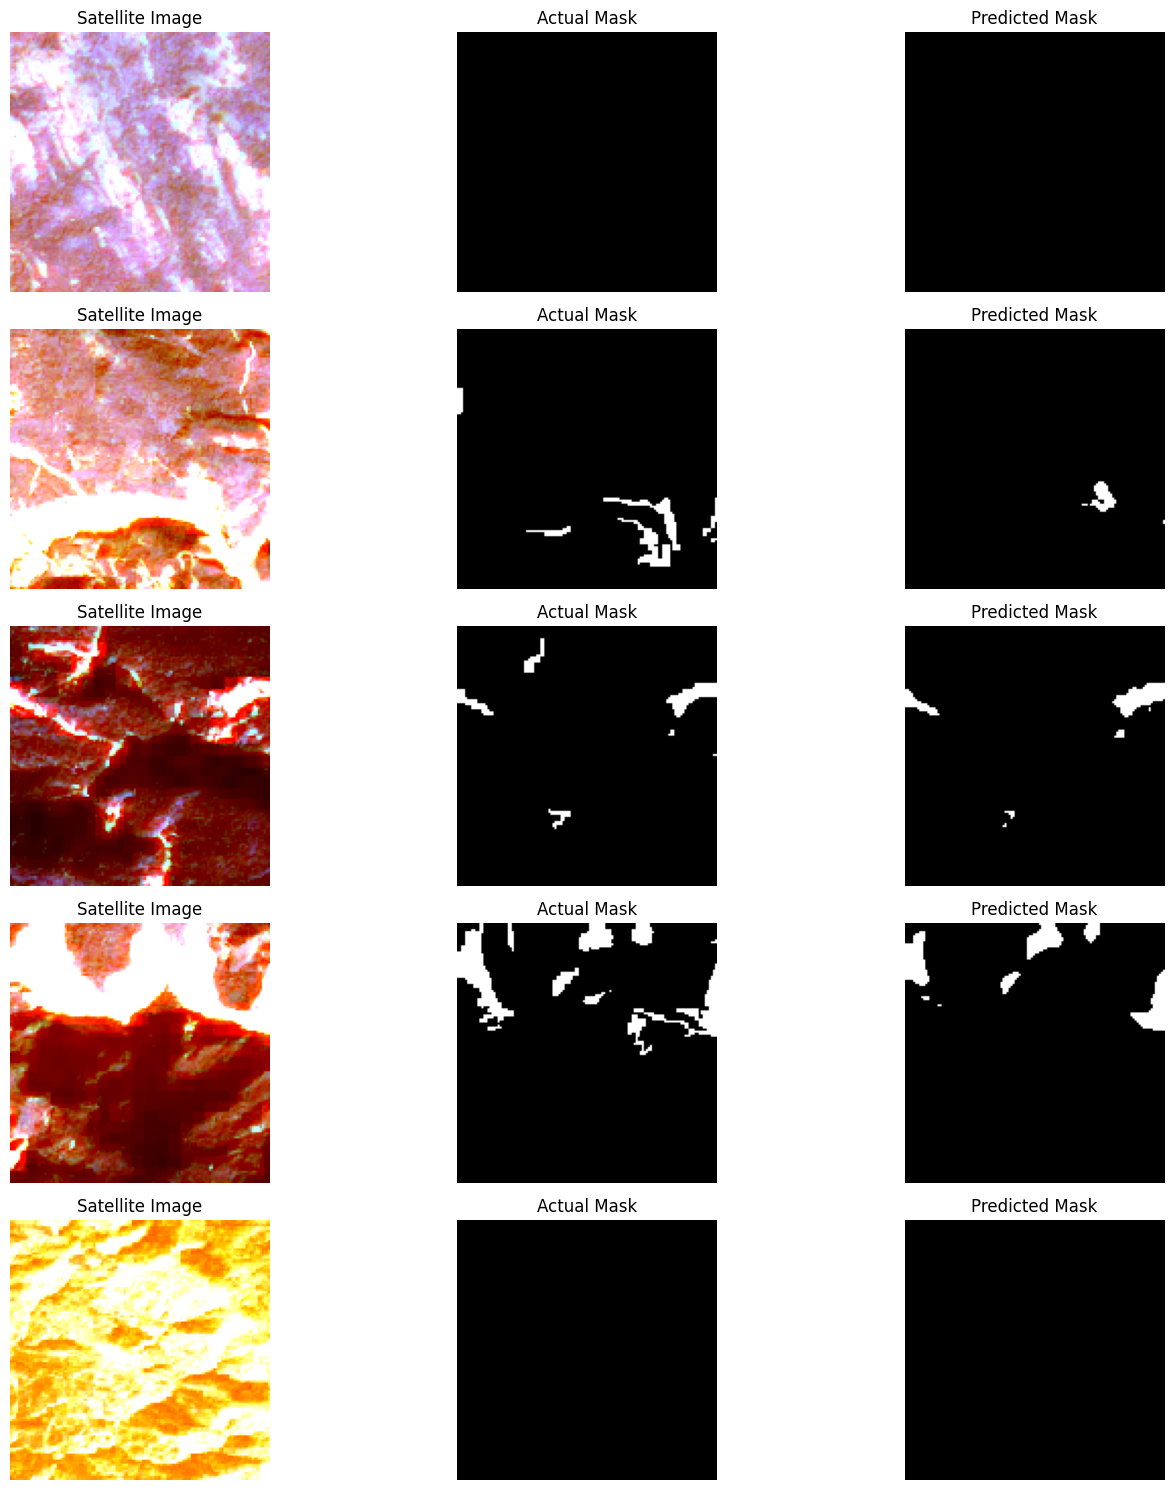

In [32]:
import matplotlib.pyplot as plt
import numpy as np

indices = np.random.choice(len(X_test), 5, replace=False)

plt.figure(figsize=(15, 15))

for i, idx in enumerate(indices):

    image = X_test[idx][:, :, :3]
    actual = Y_test[idx]

    predicted = model.predict(
        X_test[idx:idx+1],
        verbose=0
    )[0, :, :, 0]

    predicted = (predicted > 0.5).astype(np.uint8)

    plt.subplot(5, 3, i*3+1)
    plt.imshow(image)
    plt.title("Satellite Image")
    plt.axis("off")

    plt.subplot(5, 3, i*3+2)
    plt.imshow(actual, cmap="gray")
    plt.title("Actual Mask")
    plt.axis("off")

    plt.subplot(5, 3, i*3+3)
    plt.imshow(predicted, cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step


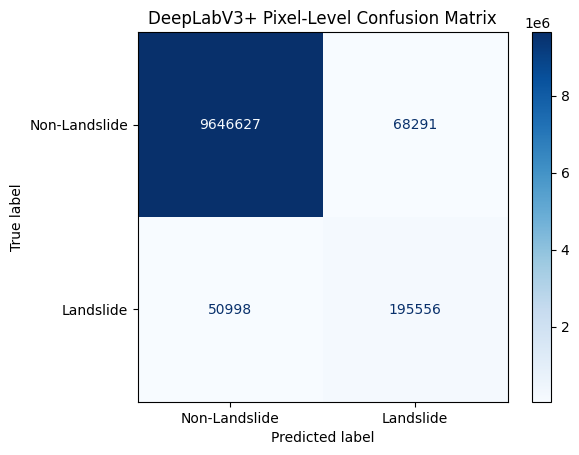

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

y_true_flat = Y_test.flatten().astype(int)
y_pred_flat = (model.predict(X_test, batch_size=8, verbose=1)[..., 0] > 0.5).flatten().astype(int)

cm = confusion_matrix(y_true_flat, y_pred_flat)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Landslide", "Landslide"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("DeepLabV3+ Pixel-Level Confusion Matrix")
plt.show()

76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step


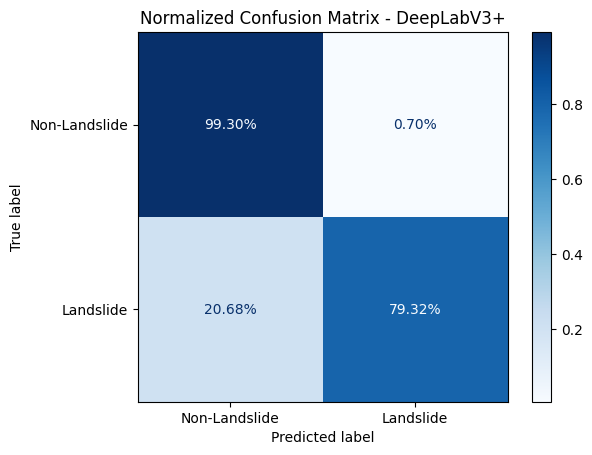

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

y_true_flat = Y_test.flatten().astype(int)

y_pred_flat = (
    model.predict(X_test, batch_size=8, verbose=1)[..., 0] > 0.5
).flatten().astype(int)

cm = confusion_matrix(
    y_true_flat,
    y_pred_flat,
    normalize='true'
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Landslide", "Landslide"]
)

disp.plot(
    cmap="Blues",
    values_format=".2%"
)

plt.title("Normalized Confusion Matrix - DeepLabV3+")
plt.show()

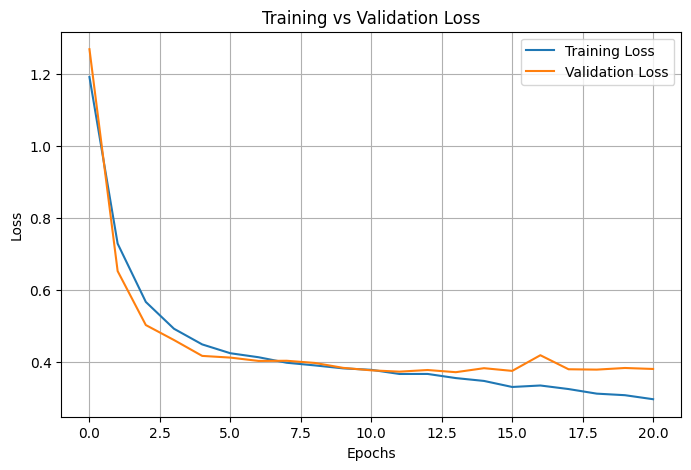

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

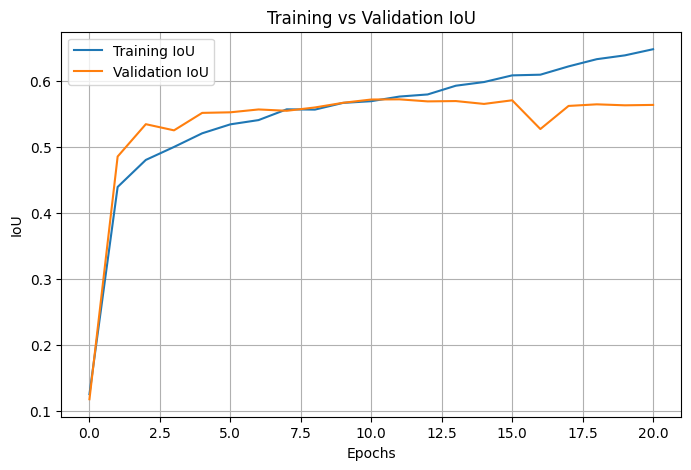

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['IoU'], label='Training IoU')
plt.plot(history.history['val_IoU'], label='Validation IoU')

plt.title('Training vs Validation IoU')
plt.xlabel('Epochs')
plt.ylabel('IoU')
plt.legend()
plt.grid(True)
plt.show()

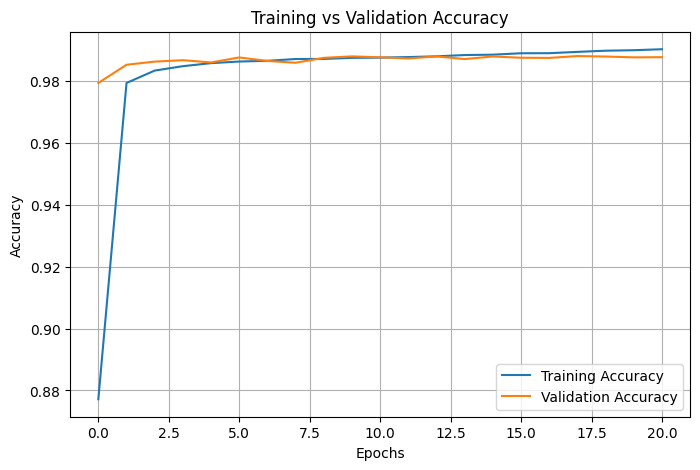

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [38]:
model.save("deeplabv3plus_landslide.keras")

print("Model saved successfully!")

Model saved successfully!


In [40]:
from IPython.display import FileLink

FileLink("deeplabv3plus_landslide.keras")

/kaggle/working/deeplabv3plus_landslide.keras

In [41]:
from tensorflow import keras

model = keras.models.load_model(
    "deeplabv3plus_landslide.keras",
    compile=False
)

In [42]:
# Check which normalization variables exist

for name in [
    "mean", "std",
    "train_mean", "train_std",
    "band_mean", "band_std",
    "mean_train", "std_train"
]:
    if name in globals():
        print(name, globals()[name].shape)

band_mean (1, 1, 1, 14)
band_std (1, 1, 1, 14)


In [43]:
import numpy as np

np.savez(
    "normalization_stats.npz",
    band_mean=band_mean,
    band_std=band_std
)

print("Normalization statistics saved!")

Normalization statistics saved!


In [44]:
from IPython.display import FileLink

FileLink("normalization_stats.npz")

/kaggle/working/normalization_stats.npz

In [45]:

import numpy as np
import json
from sklearn.metrics import confusion_matrix

# 1. Generate predictions on test set
y_prob = model.predict(X_test, batch_size=8, verbose=1)

y_pred = (y_prob[..., 0] > 0.5).astype(np.uint8)
y_true = Y_test.astype(np.uint8)

# 2. Flatten pixel values
y_true_flat = y_true.flatten()
y_pred_flat = y_pred.flatten()

# 3. Calculate raw and normalized confusion matrices
cm_raw = confusion_matrix(
    y_true_flat,
    y_pred_flat,
    labels=[0, 1]
)

cm_normalized = confusion_matrix(
    y_true_flat,
    y_pred_flat,
    labels=[0, 1],
    normalize="true"
)

# 4. Save confusion matrices
np.savez(
    "evaluation_data.npz",
    cm_raw=cm_raw,
    cm_normalized=cm_normalized
)

# 5. Save training history
history_data = {
    key: [float(x) for x in values]
    for key, values in history.history.items()
}

with open("training_history.json", "w") as f:
    json.dump(history_data, f, indent=4)

print("Evaluation data saved successfully!")
print("History metrics:", list(history.history.keys()))
print("Confusion Matrix:")
print(cm_raw)


76/76 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step
Evaluation data saved successfully!
History metrics: ['IoU', 'accuracy', 'loss', 'precision', 'recall', 'val_IoU', 'val_accuracy', 'val_loss', 'val_precision', 'val_recall', 'learning_rate']
Confusion Matrix:
[[9646627   68291]
 [  50998  195556]]


In [46]:
from IPython.display import FileLink, display

files = [
    "deeplabv3plus_landslide.keras",
    "normalization_stats.npz",
    "evaluation_data.npz",
    "training_history.json"
]

for file in files:
    display(FileLink(file))

/kaggle/working/deeplabv3plus_landslide.keras

/kaggle/working/normalization_stats.npz

/kaggle/working/evaluation_data.npz

/kaggle/working/training_history.json

In [47]:
import zipfile

with zipfile.ZipFile("training_history.zip", "w") as z:
    z.write("training_history.json")

print("ZIP created successfully!")

ZIP created successfully!


In [48]:
from IPython.display import FileLink, display

display(FileLink("training_history.zip"))

/kaggle/working/training_history.zip